# 04. H1 анализ

**H1:** чем больше токсичных соседей, тем чаще модель называет целевой текст токсичным.

Что считаем:
1. Сдвиг = ответ в батче - одиночный ответ (по метке или если есть logprobs, по logit вероятности).
2. График: доля ответов TOXIC у целевого в зависимости от доли токсичных соседей.
3. Лог рег с кластеризацией по целевому тексту: `y_batch ~ prop_toxic + одиночный ответ + позиция`. H1 подтверждается, если коэффициент при `prop_toxic` > 0 и значим.
4. Тест Макнемара: одиночный ответ vs ответ при 0 % и при 100 % токсичных соседей.

In [1]:
MODEL_KEYS = ["gigachat_lite"]  
LANG = "en"
PILOT = False         

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_DIR = Path.cwd()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
DATA_PROC = PROJECT_DIR / "data" / "processed"
DATA_RES = PROJECT_DIR / "data" / "results"
DATA_RES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 120)

import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar

FIG_DIR = PROJECT_DIR / "data" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
targets = pd.read_parquet(DATA_PROC / "targets.parquet").set_index("id")

def logit(p, eps=1e-4):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

frames = []
for mk in MODEL_KEYS:
    suffix = f"{mk}_{LANG}" + ("_pilot" if PILOT else "")
    s = pd.read_parquet(DATA_RES / f"h1_singles_{suffix}.parquet")
    b = pd.read_parquet(DATA_RES / f"h1_batches_{suffix}.parquet")
    b = b.merge(s[["id", "y_single", "p_single"]], left_on="target_id", right_on="id").drop(columns="id")
    b["model"] = mk
    frames.append(b)
df = pd.concat(frames, ignore_index=True)
df["gold"] = df["target_id"].map(targets["label"])
df["target_group"] = df["target_id"].map(targets["target_group"])
df = df.dropna(subset=["y_batch", "y_single"])
df["shift"] = df["y_batch"] - df["y_single"]                  # -1, 0, +1
df["flip"] = (df["shift"] != 0).astype(int)
has_p = df["p_batch"].notna() & df["p_single"].notna()
df.loc[has_p, "dlogit"] = logit(df.loc[has_p, "p_batch"]) - logit(df.loc[has_p, "p_single"])
print(df.groupby("model").size())

model
gigachat_lite    4498
dtype: int64


## 1. Сводная таблица по долям соседей

In [3]:
summary = (df.groupby(["model", "prop_toxic"])
             .agg(n=("y_batch", "size"),
                  toxic_single=("y_single", "mean"),
                  toxic_batch=("y_batch", "mean"),
                  mean_shift=("shift", "mean"),
                  flip_rate=("flip", "mean"),
                  mean_dlogit=("dlogit", "mean"))
             .round(3))
err = (df.assign(fp=(df["gold"] == 0) & (df["y_batch"] == 1), fn=(df["gold"] == 1) & (df["y_batch"] == 0))
         .groupby(["model", "prop_toxic"])
         .apply(lambda g: pd.Series({"FPR": g.loc[g["gold"] == 0, "fp"].mean(),
                                     "FNR": g.loc[g["gold"] == 1, "fn"].mean()}))
         .round(3))
summary.join(err)

n  toxic_single  toxic_batch  mean_shift  \
model         prop_toxic                                               
gigachat_lite 0.00        900         0.590        0.630       0.040   
              0.25        900         0.590        0.607       0.017   
              0.50        900         0.590        0.570      -0.020   
              0.75        899         0.591        0.558      -0.032   
              1.00        899         0.591        0.541      -0.050   

                          flip_rate mean_dlogit    FPR    FNR  
model         prop_toxic                                       
gigachat_lite 0.00            0.142         NaN  0.497  0.224  
              0.25            0.159         NaN  0.480  0.254  
              0.50            0.164         NaN  0.435  0.282  
              0.75            0.177         NaN  0.443  0.315  
              1.00            0.166         NaN  0.402  0.308

## 2. График
Доля ответов TOXIC у целевого текста в зависимости от доли токсичных соседей, отдельно для токсичных и нетоксичных целевых (по разметке).
Пунктир - это тот же показатель при одиночном запросе. Интервалы 95 % бутстреп по целевым текстам.

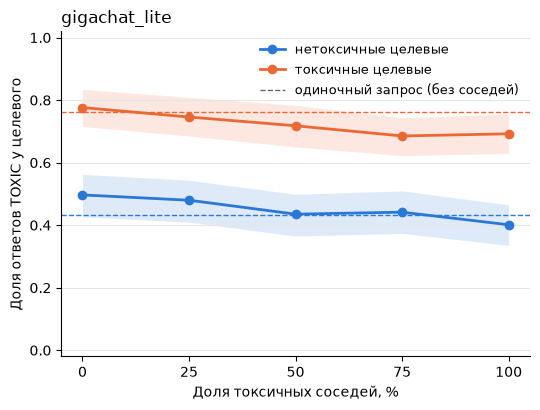

In [4]:
def boot_ci(g, n_boot=1000, seed=0):
    per_target = g.groupby("target_id")["y_batch"].mean().to_numpy()
    rng = np.random.default_rng(seed)
    means = rng.choice(per_target, (n_boot, len(per_target)), replace=True).mean(axis=1)
    return pd.Series({"mean": per_target.mean(), "lo": np.percentile(means, 2.5), "hi": np.percentile(means, 97.5)})

COLORS = {0: "#2a78d6", 1: "#eb6834"}
NAMES = {0: "нетоксичные целевые", 1: "токсичные целевые"}
models = df["model"].unique()
fig, axes = plt.subplots(1, len(models), figsize=(5.5 * len(models), 4.2), squeeze=False)
for ax, mk in zip(axes[0], models):
    d = df[df["model"] == mk]
    for g in (0, 1):
        dd = d[d["gold"] == g]
        ci = dd.groupby("prop_toxic").apply(boot_ci)
        x = ci.index * 100
        ax.plot(x, ci["mean"], marker="o", lw=2, color=COLORS[g], label=NAMES[g])
        ax.fill_between(x, ci["lo"], ci["hi"], color=COLORS[g], alpha=0.15, lw=0)
        ax.axhline(dd.drop_duplicates("target_id")["y_single"].mean(), color=COLORS[g], ls="--", lw=1)
    ax.set_title(mk, loc="left")
    ax.set_xlabel("Доля токсичных соседей, %")
    ax.set_ylabel("Доля ответов TOXIC у целевого")
    ax.set_xticks([0, 25, 50, 75, 100]); ax.set_ylim(-0.02, 1.02)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e5e5e5")
from matplotlib.lines import Line2D
h, l = axes[0][0].get_legend_handles_labels()
h.append(Line2D([], [], color="#666666", ls="--", lw=1)); l.append("одиночный запрос (без соседей)")
axes[0][0].legend(h, l, frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / f"h1_curve_{LANG}{'_pilot' if PILOT else ''}.png", dpi=150)
plt.show()

## 3. Логистическая регрессия 
GEE-логит `y_batch ~ prop_toxic + y_single + C(target_pos)`, кластеры - целевые тексты.
`y_single` учитывает, насколько текст токсичен для модели сам по себе; `target_pos` - позицию в батче.
OR при `prop_toxic` во сколько раз растут шансы ответа TOXIC при переходе от 0 % к 100 % токсичных соседей.
H1 подтверждается, если OR > 1 и p < 0.05.

Вторая строка та же модель в линейном виде: насколько процентных пунктов растёт доля ответов TOXIC при переходе от 0 до 100 %

In [5]:
import warnings
warnings.filterwarnings("ignore", message=".*separation.*")

results = []
for mk in models:
    d = df[df["model"] == mk].sort_values("target_id")
    row = dict(model=mk, n_targets=d["target_id"].nunique(),
               targets_changed=int((d.groupby("target_id")["y_batch"].nunique() > 1).sum()))
    try:
        m = smf.gee("y_batch ~ prop_toxic + y_single + C(target_pos)", groups="target_id", data=d,
                    family=sm.families.Binomial(), cov_struct=sm.cov_struct.Exchangeable()).fit()
        b, se = m.params["prop_toxic"], m.bse["prop_toxic"]
        row.update(OR_0_to_100=np.exp(b), OR_CI_low=np.exp(b - 1.96 * se), OR_CI_high=np.exp(b + 1.96 * se),
                   p_logit=m.pvalues["prop_toxic"])
    except Exception as e:
        row.update(note=f"логит не оценился: {e}")
    lin = smf.gee("y_batch ~ prop_toxic + y_single + C(target_pos)", groups="target_id", data=d,
                  cov_struct=sm.cov_struct.Exchangeable()).fit()
    bl, sel = lin.params["prop_toxic"], lin.bse["prop_toxic"]
    row.update(pp_0_to_100=100 * bl, pp_CI_low=100 * (bl - 1.96 * sel), pp_CI_high=100 * (bl + 1.96 * sel),
               p_linear=lin.pvalues["prop_toxic"])
    results.append(row)
res_h1 = pd.DataFrame(results)
res_h1.round(4)

,model,n_targets,targets_changed,OR_0_to_100,OR_CI_low,OR_CI_high,p_logit,pp_0_to_100,pp_CI_low,pp_CI_high,p_linear
0,gigachat_lite,300,148,0.5001,0.4192,0.5965,0.0,-9.1523,-11.5715,-6.7331,0.0


Для моделей с logprobs — то же на непрерывной шкале: средний сдвиг logit в зависимости от доли соседей (линейная GEE).

In [6]:
for mk in models:
    d = df[(df["model"] == mk) & df["dlogit"].notna()].sort_values("target_id")
    if len(d) == 0:
        print(mk, "— нет logprobs, пропускаем"); continue
    m = smf.gee("dlogit ~ prop_toxic + C(target_pos)", groups="target_id", data=d,
                cov_struct=sm.cov_struct.Exchangeable()).fit()
    print(f"{mk}: сдвиг logit при 0→100 % = {m.params['prop_toxic']:.3f} (p = {m.pvalues['prop_toxic']:.4g})")

gigachat_lite — нет logprobs, пропускаем


## 4. Тест Макнемара
Для каждого целевого — метка большинства по 3 повторам при 0 % и при 100 % токсичных соседей; сравниваем с одиночной меткой.

In [7]:
for mk in models:
    for prop in (0.0, 1.0):
        d = df[(df["model"] == mk) & (df["prop_toxic"] == prop)]
        maj = d.groupby("target_id").agg(y_single=("y_single", "first"), y_batch=("y_batch", lambda s: int(s.mean() > 0.5)))
        tab = pd.crosstab(maj["y_single"], maj["y_batch"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
        res = mcnemar(tab.to_numpy(), exact=True)
        print(f"{mk}, {prop:.0%} токсичных соседей: стало TOXIC {tab.loc[0, 1]}, стало NOT {tab.loc[1, 0]}, p = {res.pvalue:.4g}")

gigachat_lite, 0% токсичных соседей: стало TOXIC 28, стало NOT 10, p = 0.005098
gigachat_lite, 100% токсичных соседей: стало TOXIC 13, стало NOT 28, p = 0.02753
